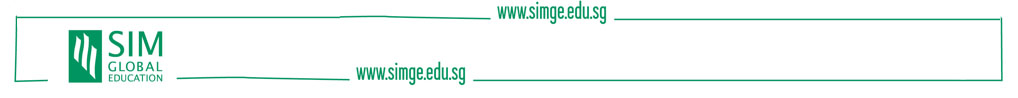

# Word Cloud & Stemmer

In [20]:
import pandas as pd
import nltk
from nltk.corpus import webtext
from nltk.probability import FreqDist
from wordcloud import WordCloud  # Is not installed.
import matplotlib.pyplot as plt
from nltk import sent_tokenize, word_tokenize

In [21]:
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\julianlin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\julianlin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [22]:
myWords =[]
#data = pd.read_csv('HanselNGretel.txt')
f = open('HanselNGretel.txt', 'r')
data=f.read()

#index = data.index
#number_of_rows=len(index)
#print(number_of_rows)

#### Comparing Split with Tokenize

In [23]:
myWords=data.split(" ")


In [24]:
Mywords=nltk.word_tokenize(data)

In [25]:
Mywords

['Hard',
 'by',
 'a',
 'great',
 'forest',
 'dwelt',
 'a',
 'poor',
 'wood-cutter',
 'with',
 'his',
 'wife',
 'and',
 'his',
 'two',
 'children',
 '.',
 'The',
 'boy',
 'was',
 'called',
 'Hansel',
 'and',
 'the',
 'girl',
 'Gretel',
 '.',
 'He',
 'had',
 'little',
 'to',
 'bite',
 'and',
 'to',
 'break',
 ',',
 'and',
 'once',
 'when',
 'great',
 'dearth',
 'fell',
 'on',
 'the',
 'land',
 ',',
 'he',
 'could',
 'no',
 'longer',
 'procure',
 'even',
 'daily',
 'bread',
 '.',
 'Now',
 'when',
 'he',
 'thought',
 'over',
 'this',
 'by',
 'night',
 'in',
 'his',
 'bed',
 ',',
 'and',
 'tossed',
 'about',
 'in',
 'his',
 'anxiety',
 ',',
 'he',
 'groaned',
 'and',
 'said',
 'to',
 'his',
 'wife',
 ':',
 'â€˜What',
 'is',
 'to',
 'become',
 'of',
 'us',
 '?',
 'How',
 'are',
 'we',
 'to',
 'feed',
 'our',
 'poor',
 'children',
 ',',
 'when',
 'we',
 'no',
 'longer',
 'have',
 'anything',
 'even',
 'for',
 'ourselves',
 '?',
 'â€™',
 'â€˜Iâ€™ll',
 'tell',
 'you',
 'what',
 ',',
 'husband',

#### Counting Word

In [26]:
data_analysis=nltk.FreqDist(myWords)

In [27]:
data_analysis

FreqDist({'the': 159, 'and': 154, 'to': 72, 'a': 43, 'they': 42, 'of': 41, 'had': 40, 'was': 33, 'in': 32, 'little': 30, ...})

#### Finding Word is is greater than 5 e.g., "the" is only 3, "little" is 5 

In [28]:
filter_words = dict([m, n] for m, n in data_analysis.items() if len (m) > 5)

In [29]:
filt_word={}
for Wrd, Cnt in data_analysis.items():
    #print(Wrd,Cnt)
    if len(Wrd) > 5:
        filt_word[Wrd]=Cnt


#### Using dict

In [30]:
my_dict = dict([(1,'apple'), (2,'ball')])
params = {'a': 1, 'b': 2}
new_params = {**params, **{'c': 3}}

In [31]:
new_params = {**new_params, **my_dict}

In [34]:
filt_word1={}
for Wrd, Cnt in data_analysis.items():
    #print(Wrd,Cnt)
    if len(Wrd) > 5:
        filt_word1 = {**filt_word1, **{Wrd:Cnt}}


In [36]:
filter_words == filt_word == filt_word1 

True

#### Generating WordCloud Object

In [176]:
wcloud=WordCloud().generate_from_frequencies(filter_words)

In [185]:
wcloud.background_color='black'

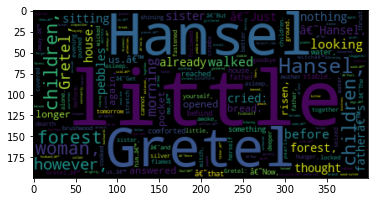

In [186]:
plt.imshow(wcloud, interpolation='bilinear')
#plt.axis("off")
plt.axis("on")
(-1.5, 200, 100, -2.5)
plt.show()

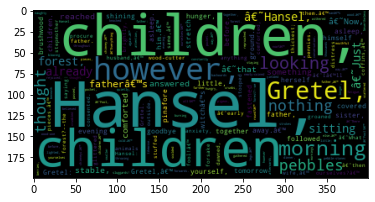

In [144]:
plt.imshow(wcloud)

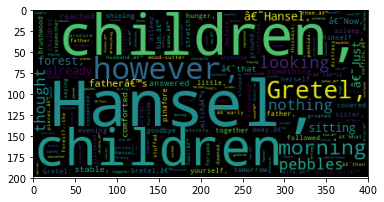

In [145]:
plt.imshow(wcloud)
#plt.axis([-1.5, 200, 100, -2.5])
plt.axis([0, 400, 200, 0])
#plt.axis("off")
plt.show()


# Stemmer

In [193]:
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.stem import LancasterStemmer

In [199]:
e_words=['dance', 'danced', 'dancing', 'dancer', 'dances']

#### Porter's Stemmer

In [203]:
ps =PorterStemmer()
##http://www.tartarus.org/~martin/PorterStemmer/ 
##    Porter, M. "An algorithm for suffix stripping."
##    Program 14.3 (1980): 130-137.

In [205]:
for w in e_words:
    rootWord=ps.stem(w)
    print(rootWord)

danc
danc
danc
dancer
danc


In [206]:
[ps.stem(w) for w in e_words]

['danc', 'danc', 'danc', 'dancer', 'danc']

#### Wordnet's Lemmtizer

In [207]:
lemmatizer = WordNetLemmatizer()

In [216]:
print("dances:", lemmatizer.lemmatize('dance'))
print("dances:", lemmatizer.lemmatize('dances'))

print("dancing:", lemmatizer.lemmatize('dancing', pos="v"))
print("dancing:", lemmatizer.lemmatize('dancing', pos='a'))

dances: dance
dances: dance
dancing: dance
dancing: dancing


In [208]:
e_words

['dance', 'danced', 'dancing', 'dancer', 'dances']

In [212]:
[lemmatizer.lemmatize(i) for i in e_words]

['dance', 'danced', 'dancing', 'dancer', 'dance']

#### LancasterStemmer

In [219]:
st?

In [194]:
st = LancasterStemmer()

In [226]:
st.stem("happiness")

'happy'

In [227]:
st.stem("took")

'took'

In [228]:
st.stem("crying")

'cry'

In [229]:
st.stem("sickness")

'sick'

In [230]:
st.stem("happier")

'happy'

### More Stemming Demo
http://text-processing.com/demo/stem/